In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

In [4]:
# Load CSV with two header rows
try:
    df = pd.read_excel("../Datasets/excel/GPS_Dataset_3D_8_Channels_Authentic_and_Simulated.xlsx", header=[0, 1])
except FileNotFoundError:
    print("Error: The file '../Datasets/excel/GPS_Dataset_3D_8_Channels_Authentic_and_Simulated.xlsx' was not found.")
    print("Please make sure the path is correct.")
    exit()

# List of variables/features to plot (excluding 'Output')
features = [
    "PRN", "Carrier_Doppler_hz", "Pseudorange_m", "RX_time", "TOW_at_current_symbol_s",
    "Carrier_phase_cycles", "EC", "LC", "PC", "PIP", "PQP", "TCD", "CN0"
]

In [5]:
print(df.columns.tolist())

[('PRN', 'ch0'), ('PRN', 'ch1'), ('PRN', 'ch2'), ('PRN', 'ch3'), ('PRN', 'ch4'), ('PRN', 'ch5'), ('PRN', 'ch6'), ('PRN', 'ch7'), ('Carrier_Doppler_hz', 'ch0'), ('Carrier_Doppler_hz', 'ch1'), ('Carrier_Doppler_hz', 'ch2'), ('Carrier_Doppler_hz', 'ch3'), ('Carrier_Doppler_hz', 'ch4'), ('Carrier_Doppler_hz', 'ch5'), ('Carrier_Doppler_hz', 'ch6'), ('Carrier_Doppler_hz', 'ch7'), ('Pseudorange_m', 'ch0'), ('Pseudorange_m', 'ch1'), ('Pseudorange_m', 'ch2'), ('Pseudorange_m', 'ch3'), ('Pseudorange_m', 'ch4'), ('Pseudorange_m', 'ch5'), ('Pseudorange_m', 'ch6'), ('Pseudorange_m', 'ch7'), ('RX_time', 'ch0'), ('RX_time', 'ch1'), ('RX_time', 'ch2'), ('RX_time', 'ch3'), ('RX_time', 'ch4'), ('RX_time', 'ch5'), ('RX_time', 'ch6'), ('RX_time', 'ch7'), ('TOW_at_current_symbol_s', 'ch0'), ('TOW_at_current_symbol_s', 'ch1'), ('TOW_at_current_symbol_s', 'ch2'), ('TOW_at_current_symbol_s', 'ch3'), ('TOW_at_current_symbol_s', 'ch4'), ('TOW_at_current_symbol_s', 'ch5'), ('TOW_at_current_symbol_s', 'ch6'), ('T

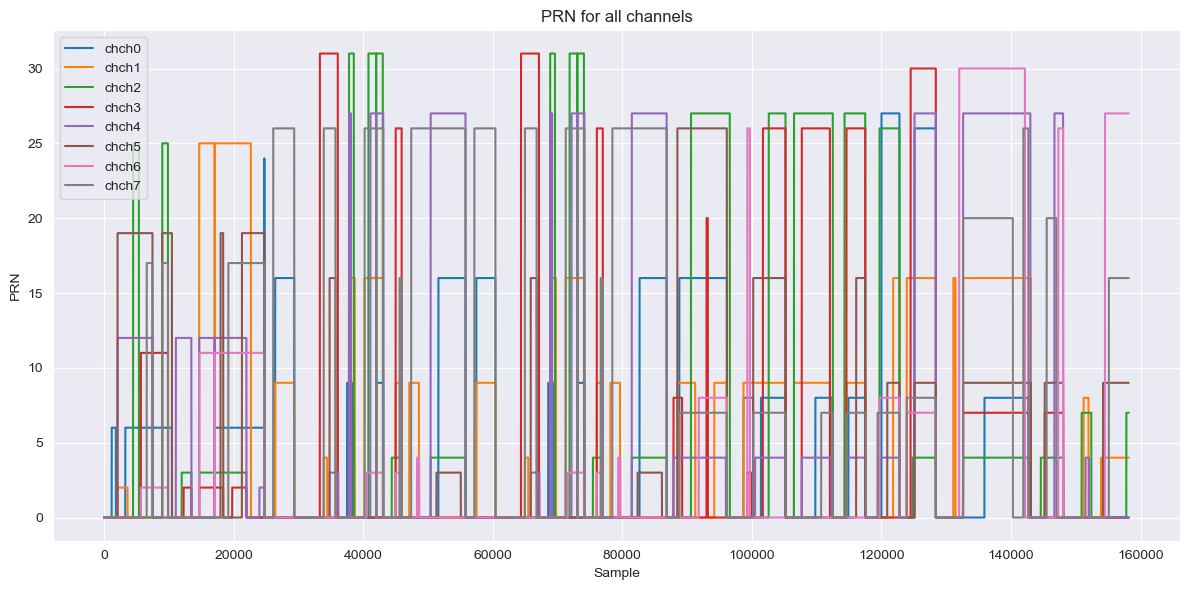

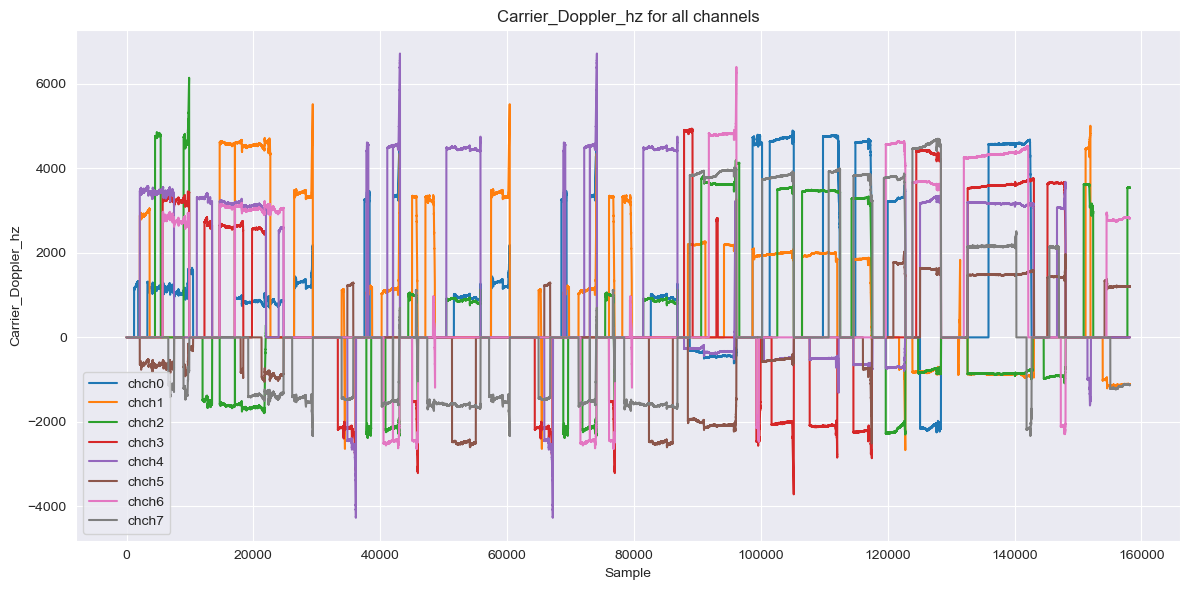

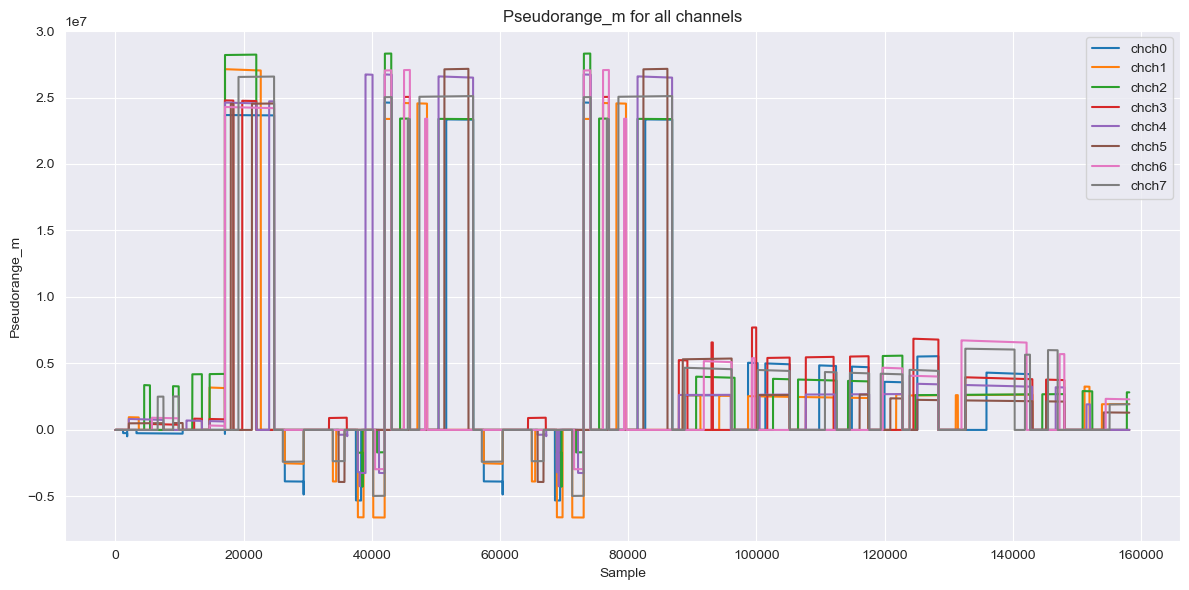

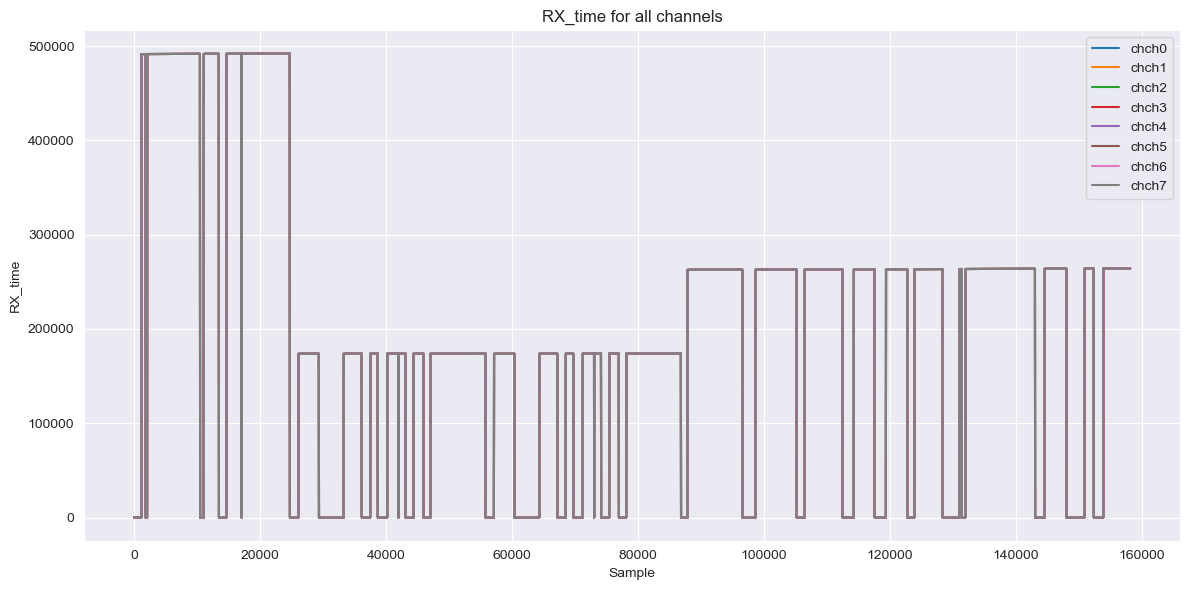

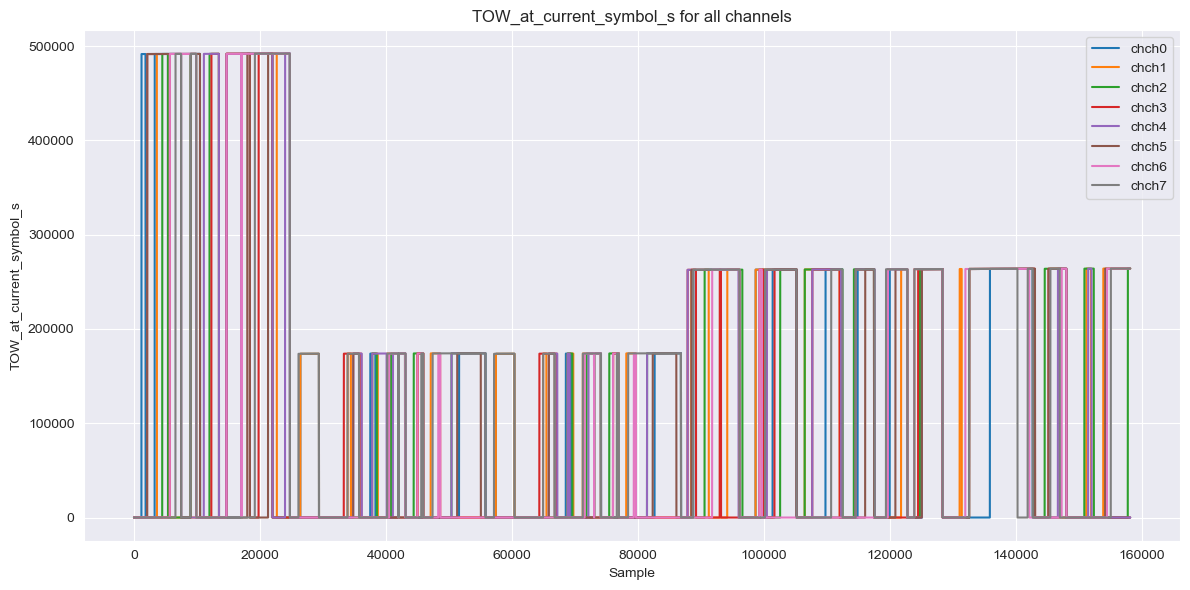

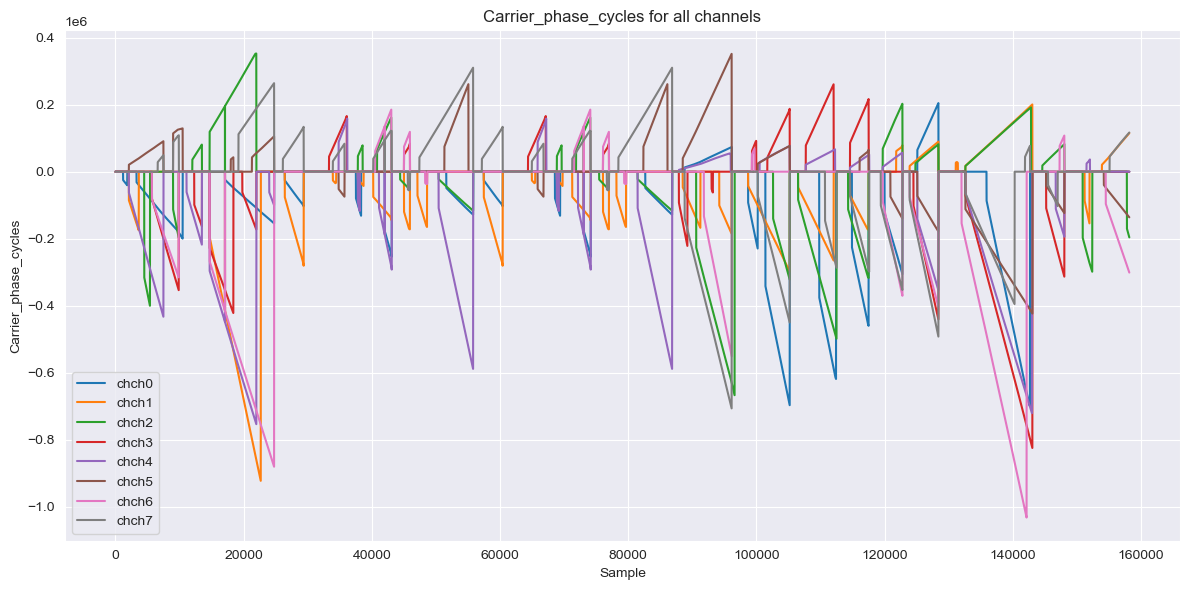

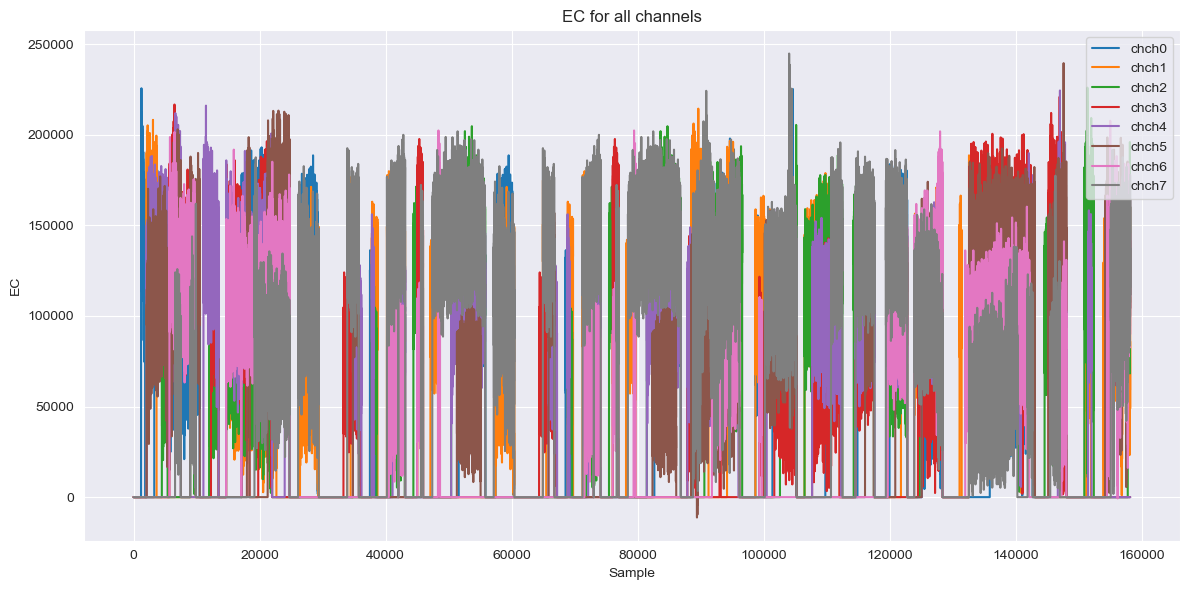

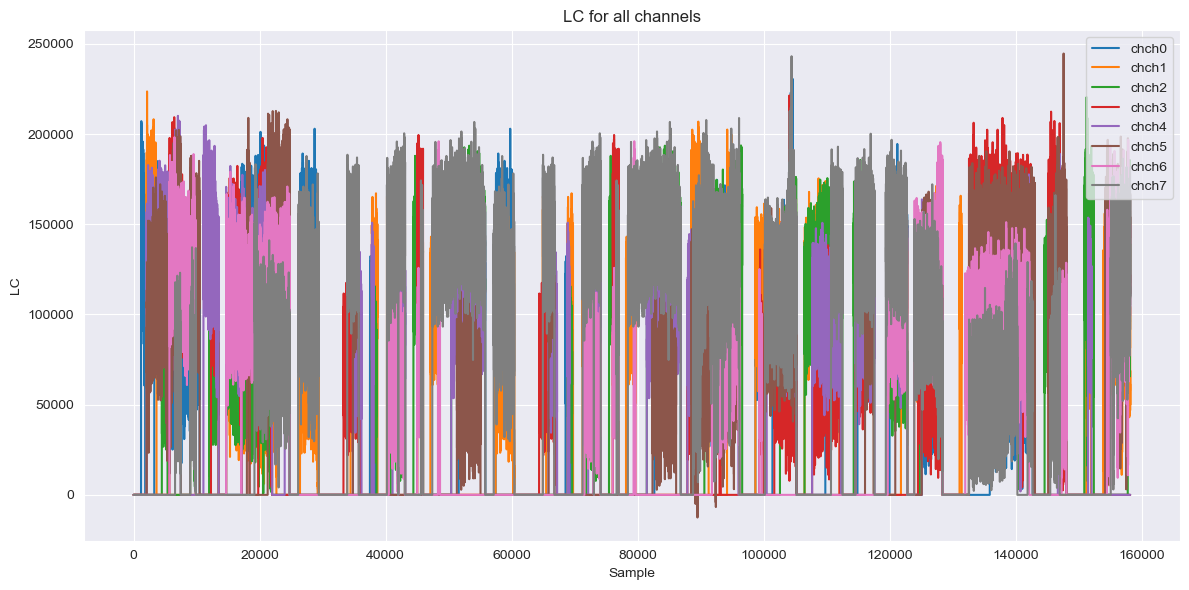

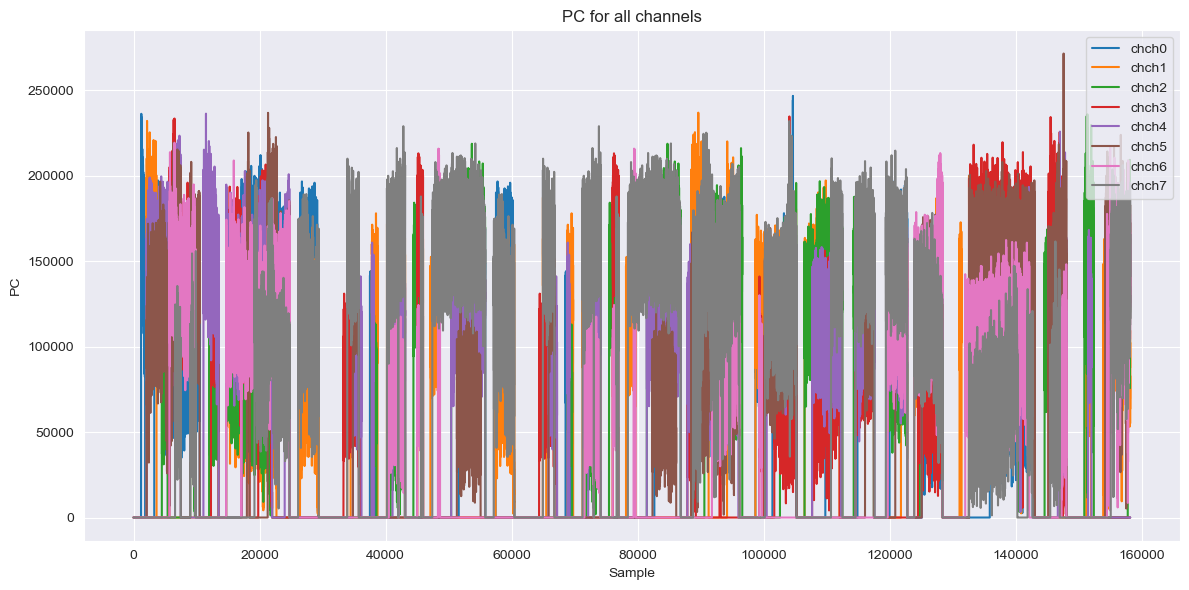

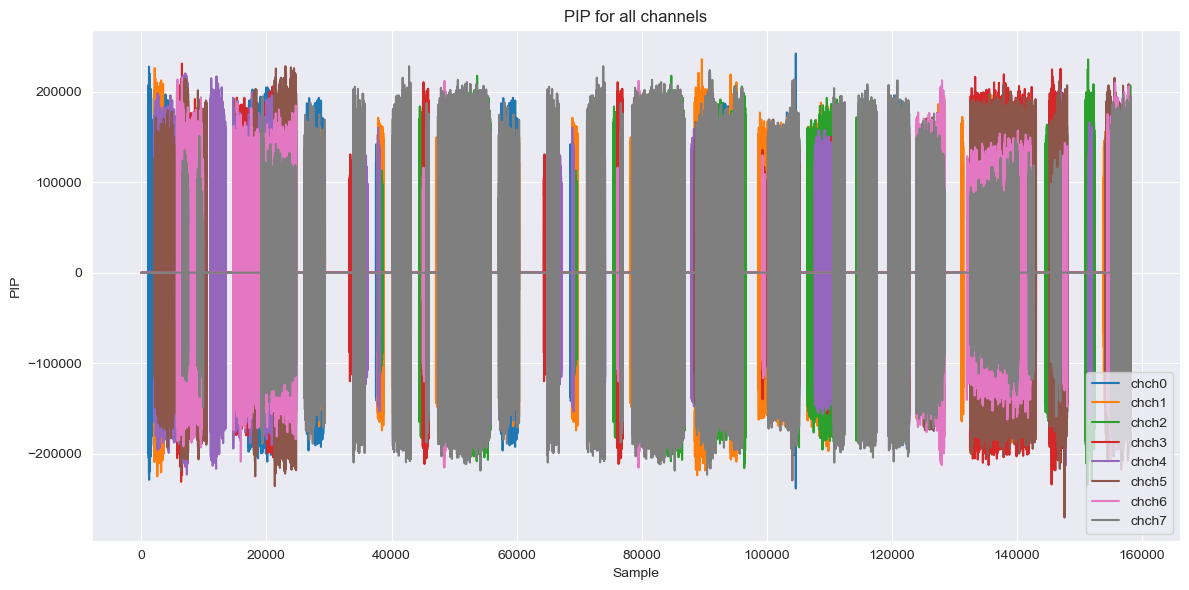

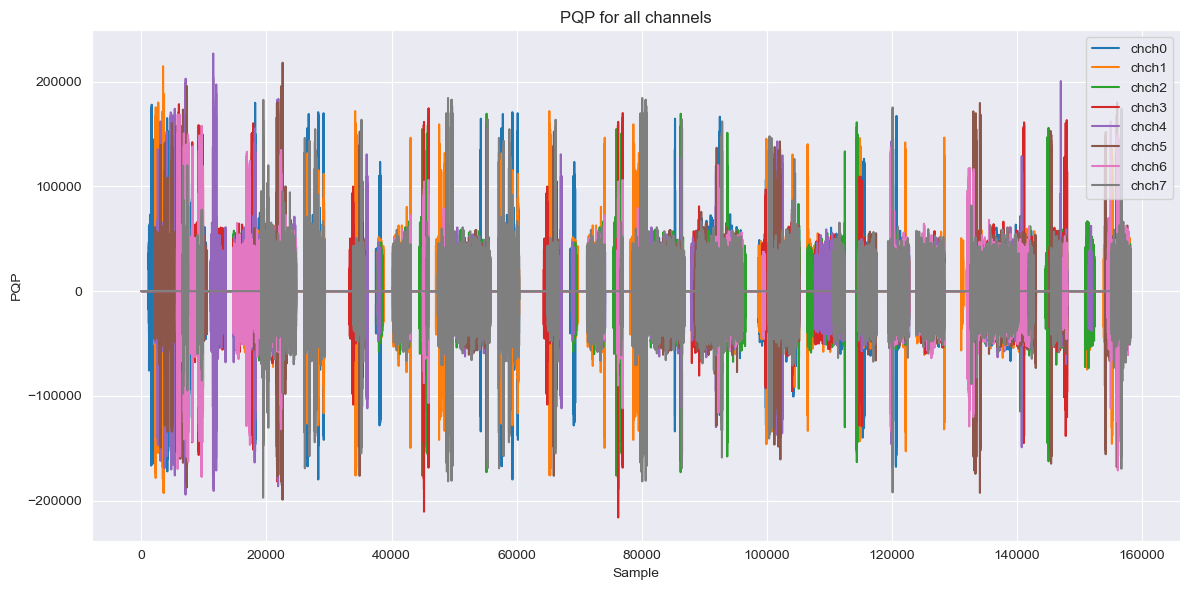

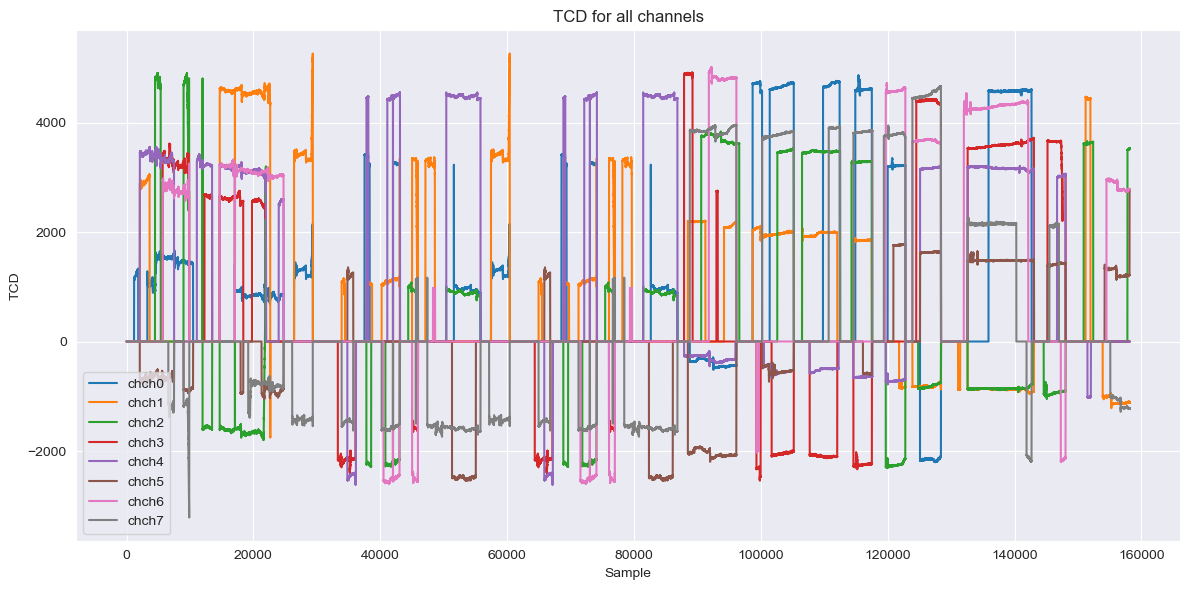

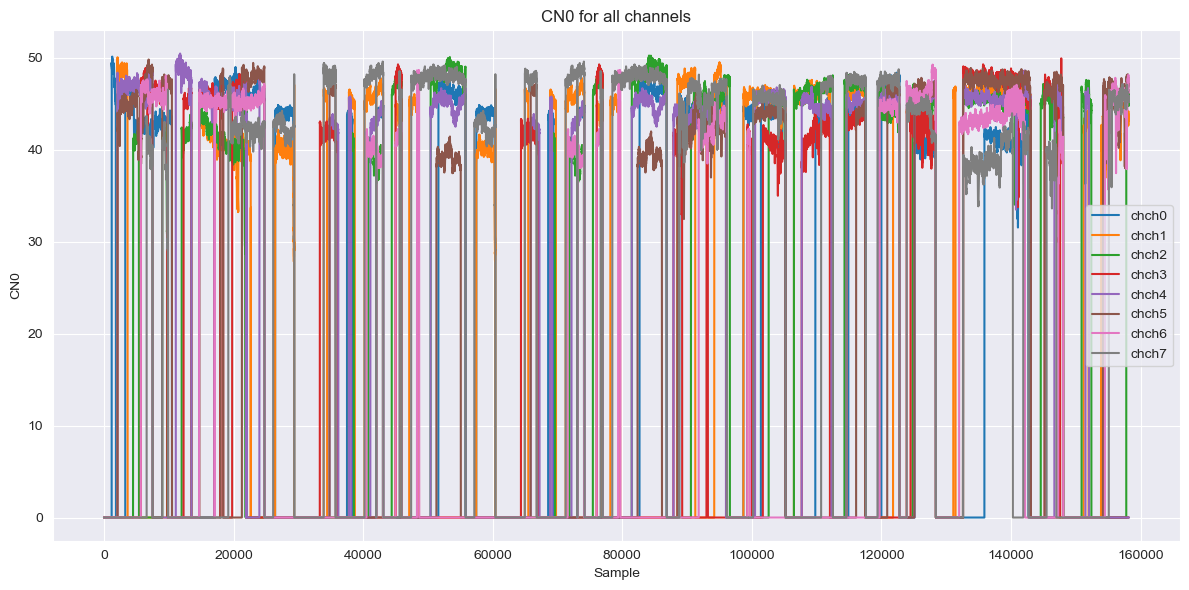

In [6]:
for features in features:
    # Find all channel columns for this variable
    channels = [col[1] for col in df.columns if col[0] == features]
    if not channels:
        continue  # Skip if none found

    plt.figure(figsize=(12, 6))
    for ch in channels:
        series = df[(features, ch)]
        if pd.api.types.is_numeric_dtype(series):
            plt.plot(series, label=f"ch{ch}")
    plt.xlabel("Sample")
    plt.ylabel(features)
    plt.title(f"{features} for all channels")
    plt.legend()
    plt.tight_layout()
    plt.show()

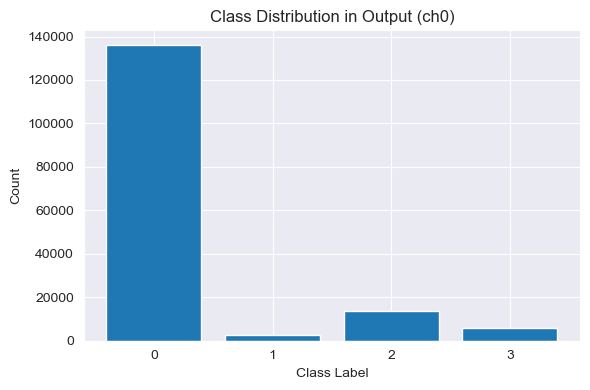

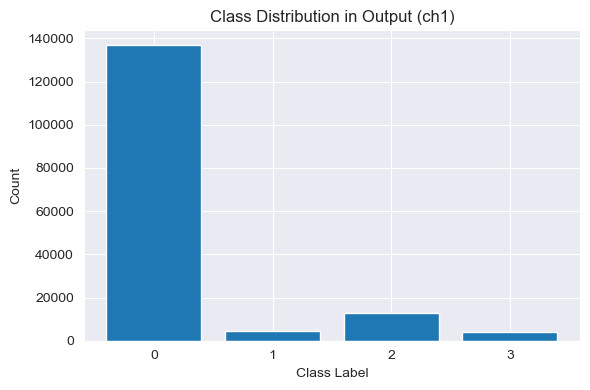

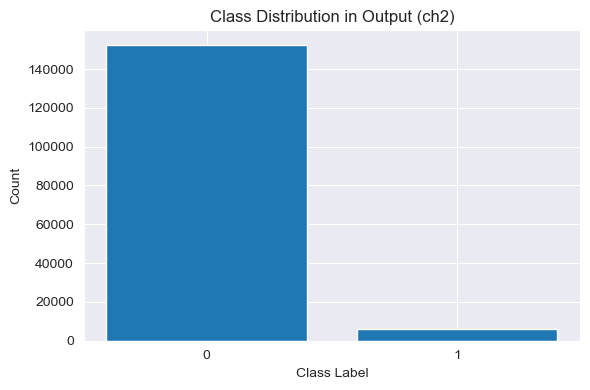

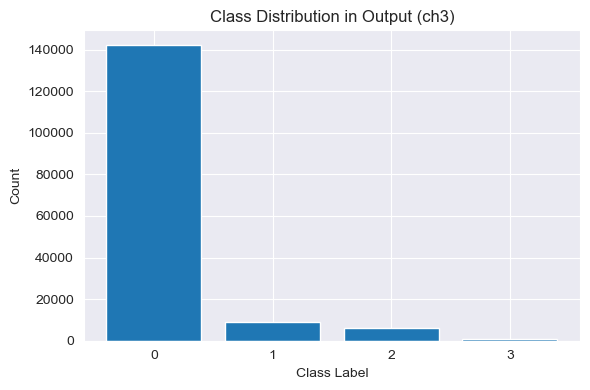

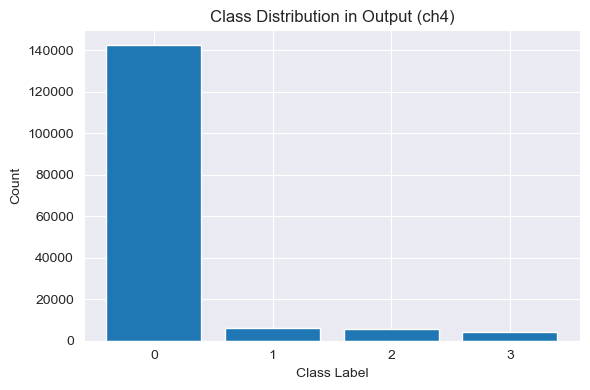

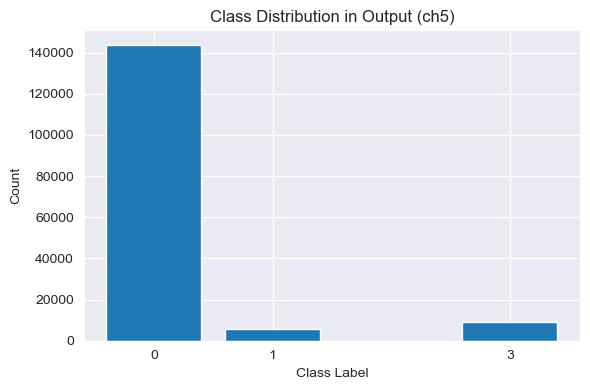

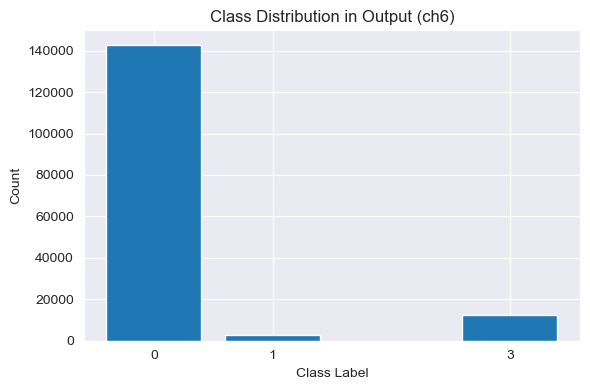

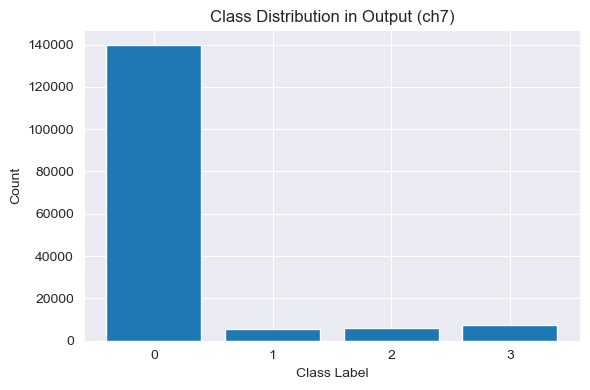

In [7]:
output_channels = [col[1] for col in df.columns if col[0] == "Output"]

for ch in output_channels:
    output_series = df[('Output', ch)]

    # Clean and extract class labels
    output_series = output_series.astype(str).str.strip()
    output_series = output_series.str.extract(r'(\d+)')[0]
    output_series = pd.to_numeric(output_series, errors='coerce')

    vc = output_series.value_counts().sort_index()
    vc.index = vc.index.astype(int)

    plt.figure(figsize=(6, 4))
    plt.bar(vc.index, vc.values)
    plt.xlabel("Class Label")
    plt.ylabel("Count")
    plt.title(f"Class Distribution in Output ({ch})")
    plt.xticks(vc.index)
    plt.tight_layout()
    plt.show()

# Class meanings:
# 0 = authentic GPS signal
# 1 = simple spoofing attack
# 2 = intermediate spoofing attack
# 3 = advanced spoofing attack

In [8]:
for ch in output_channels:
    series = df[('Output', ch)].astype(str).str.strip().str.extract(r'(\d+)')[0]
    series = pd.to_numeric(series, errors='coerce')
    class_labels = sorted(series.dropna().unique())
    class_labels = [int(x) for x in class_labels]
    print(f"Channel {ch}: Class labels: {class_labels}")

Channel ch0: Class labels: [0, 1, 2, 3]
Channel ch1: Class labels: [0, 1, 2, 3]
Channel ch2: Class labels: [0, 1]
Channel ch3: Class labels: [0, 1, 2, 3]
Channel ch4: Class labels: [0, 1, 2, 3]
Channel ch5: Class labels: [0, 1, 3]
Channel ch6: Class labels: [0, 1, 3]
Channel ch7: Class labels: [0, 1, 2, 3]


In [9]:
# Label column
y = df[('Output', 'ch0')].astype(str).str.strip().str.extract(r'(\d+)')[0]
y = pd.to_numeric(y, errors='coerce')

# Drop only the Output ch0 column
X = df.drop(('Output', 'ch0'), axis=1)

# K-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    print(f"\nFold {fold}:")
    print("Train class distribution:")
    print(y_train.value_counts(normalize=True).sort_index())
    print("Test class distribution:")
    print(y_test.value_counts(normalize=True).sort_index())


Fold 1:
Train class distribution:
0
0    0.859942
1    0.015805
2    0.086321
3    0.037933
Name: proportion, dtype: float64
Test class distribution:
0
0    0.859965
1    0.015805
2    0.086297
3    0.037933
Name: proportion, dtype: float64

Fold 2:
Train class distribution:
0
0    0.859942
1    0.015805
2    0.086321
3    0.037933
Name: proportion, dtype: float64
Test class distribution:
0
0    0.859965
1    0.015805
2    0.086297
3    0.037933
Name: proportion, dtype: float64

Fold 3:
Train class distribution:
0
0    0.859949
1    0.015805
2    0.086313
3    0.037933
Name: proportion, dtype: float64
Test class distribution:
0
0    0.859934
1    0.015805
2    0.086328
3    0.037933
Name: proportion, dtype: float64

Fold 4:
Train class distribution:
0
0    0.859949
1    0.015805
2    0.086313
3    0.037933
Name: proportion, dtype: float64
Test class distribution:
0
0    0.859934
1    0.015805
2    0.086328
3    0.037933
Name: proportion, dtype: float64

Fold 5:
Train class distributio